In [1]:
# ---------------------------------------------------------------------------
# # Question 1.0 – Imports & Dataset Load
# ---------------------------------------------------------------------------


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, GroupKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import make_scorer, mean_absolute_error
from sklearn.cluster import AgglomerativeClustering


from ucimlrepo import fetch_ucirepo

# Explore
print("\n" + "="*70)
print("IMPORTS & DATASET LOAD")
print("="*70)

# Fetch dataset (UCI Parkinson's Telemonitoring)
parkinsons_telemonitoring = fetch_ucirepo(id=189)

# Data (as pandas DataFrames)
X = parkinsons_telemonitoring.data.features
y = parkinsons_telemonitoring.data.targets

print(f"Features shape: {X.shape} | Targets shape: {y.shape}")


IMPORTS & DATASET LOAD
Features shape: (5875, 19) | Targets shape: (5875, 2)


In [2]:
# ---------------------------------------------------------------------------
# # Question 1.1 – EDA & Remove motor_UPDRS
# ---------------------------------------------------------------------------


from sklearn.preprocessing import StandardScaler

# Explore
print("\n" + "="*70)
print("PREP & GROUPED CV")
print("="*70)

# Target (remove motor_UPDRS from modeling; we predict total_UPDRS)
y_total = y['total_UPDRS'].copy()

# Build modeling features (drop labels/ID if present)
drop_cols = [c for c in ['motor_UPDRS', 'total_UPDRS', 'subject#', 'subject', 'subject_id'] if c in X.columns]
X_work = X.drop(columns=drop_cols, errors='ignore').copy()

# Infer segments then cluster
if 'test_time' not in X.columns:
    raise RuntimeError("Cannot infer subject groups: 'test_time' is missing and no subject column available.")

t = X['test_time'].to_numpy()
reset = np.r_[True, t[1:] < t[:-1]]     # True at first row and wherever test_time decreases
segment_id = np.cumsum(reset)           # 1,1,1,... then 2,2,2,...

summary_cols = [c for c in X.columns if c not in ['test_time']]
seg_df = pd.DataFrame({'segment_id': segment_id}).join(X[summary_cols])
agg = seg_df.groupby('segment_id').median(numeric_only=True)

# Standardize
scaler_sig = StandardScaler()
sig_scaled = scaler_sig.fit_transform(agg)

n_target_subjects = 42
clust = AgglomerativeClustering(n_clusters=n_target_subjects, linkage='ward')
seg_to_subject = clust.fit_predict(sig_scaled)

# Map each row
unique_segments = agg.index.to_numpy()
seg_map = dict(zip(unique_segments, seg_to_subject))
groups = np.vectorize(seg_map.get)(segment_id)

# CV scorer and strategy
scorer_mae = make_scorer(mean_absolute_error, greater_is_better=False)
cv = GroupKFold(n_splits=min(10, len(np.unique(groups))))
cv_kwargs = {'groups': groups}

# Explore
print(f"Rows: {len(X_work):,} | Columns: {X_work.shape[1]}")
print(f"Inferred contiguous segments: {len(unique_segments):,}")
print(f"Clustered subjects (groups): {len(np.unique(groups)):,}")
print(f"Using GroupKFold folds: {cv.n_splits}")



PREP & GROUPED CV
Rows: 5,875 | Columns: 19
Inferred contiguous segments: 266
Clustered subjects (groups): 42
Using GroupKFold folds: 10


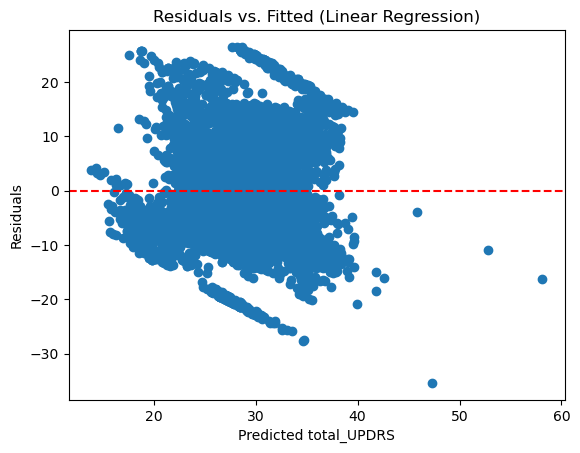

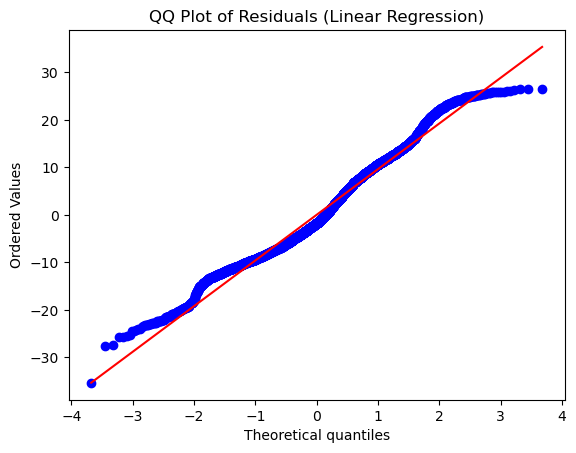


LINEAR REGRESSION – CV MAE
MAE: 9.015 ± 1.999


In [4]:
# ---------------------------------------------------------------------------
# Question 2.0 – Linear Regression with Cross-Validation
# ---------------------------------------------------------------------------

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

# Linear Regression pipeline
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LinearRegression())
])

# Cross-validated MAE scores
lr_mae_scores = cross_val_score(lr_pipe, X_work, y_total,
                                scoring=scorer_mae, cv=cv, **cv_kwargs)

from scipy import stats

# Fit and predict
lr_pipe.fit(X_work, y_total)
y_pred = lr_pipe.predict(X_work)
residuals = y_total - y_pred

# 1) Residuals vs. fitted
plt.scatter(y_pred, residuals)
plt.axhline(0, color='red', linestyle='--')
plt.title("Residuals vs. Fitted (Linear Regression)")
plt.xlabel("Predicted total_UPDRS")
plt.ylabel("Residuals")
plt.show()

# 2) QQ plot
stats.probplot(residuals, dist="norm", plot=plt)
plt.title("QQ Plot of Residuals (Linear Regression)")
plt.show()

# Report
print("\n" + "="*70)
print("LINEAR REGRESSION – CV MAE")
print("="*70)
print(f"MAE: {-lr_mae_scores.mean():.3f} ± {lr_mae_scores.std():.3f}")


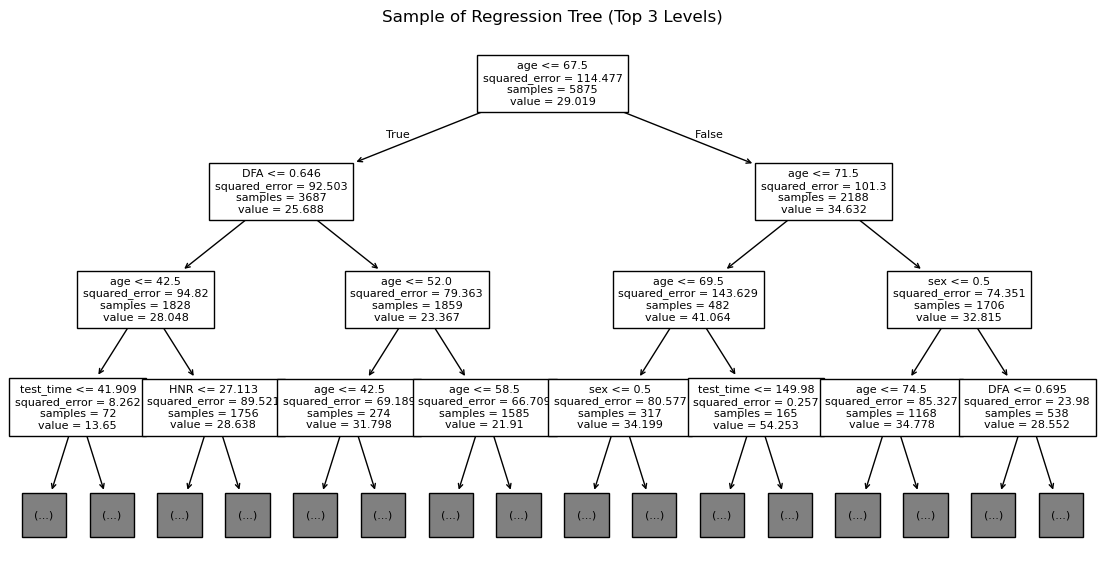


REGRESSION TREE – CV MAE
MAE: 7.160 ± 4.059


In [5]:
# ---------------------------------------------------------------------------
# Question 3.0 – Regression Tree with Cross-Validation
# ---------------------------------------------------------------------------

from sklearn.tree import DecisionTreeRegressor

# Regression tree model
tree_model = DecisionTreeRegressor(random_state=39, min_samples_leaf=5)

# Cross-validated MAE scores
tree_mae_scores = cross_val_score(tree_model, X_work, y_total,
                                  scoring=scorer_mae, cv=cv, **cv_kwargs)

from sklearn.tree import plot_tree

tree_model.fit(X_work, y_total)
plt.figure(figsize=(14,7))
plot_tree(tree_model, max_depth=3, fontsize=8, feature_names=X_work.columns)
plt.title("Sample of Regression Tree (Top 3 Levels)")
plt.show()

# Report
print("\n" + "="*70)
print("REGRESSION TREE – CV MAE")
print("="*70)
print(f"MAE: {-tree_mae_scores.mean():.3f} ± {tree_mae_scores.std():.3f}")


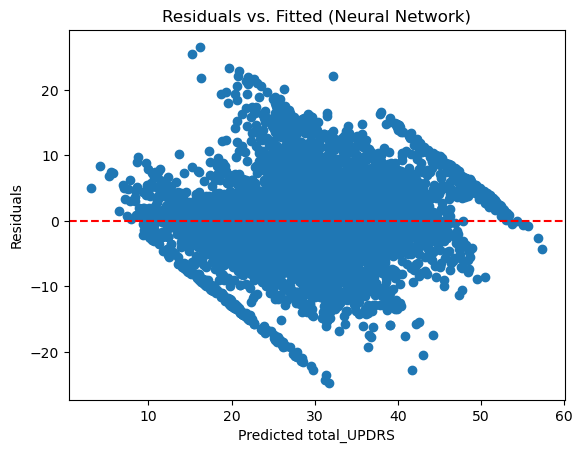


NEURAL NETWORK – CV MAE
MAE: 9.598 ± 3.380


In [6]:
# ---------------------------------------------------------------------------
# Question 4.0 – Neural Network with Cross-Validation
# ---------------------------------------------------------------------------

from sklearn.neural_network import MLPRegressor

# Neural network pipeline
nn_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('nn', MLPRegressor(hidden_layer_sizes=(30,),
                        activation='relu',
                        max_iter=5000,
                        random_state=21))
])

# Cross-validated MAE scores
nn_mae_scores = cross_val_score(nn_pipe, X_work, y_total,
                                scoring=scorer_mae, cv=cv, **cv_kwargs)

# Quick residual diagnostic
nn_pipe.fit(X_work, y_total)
y_pred_nn = nn_pipe.predict(X_work)
residuals_nn = y_total - y_pred_nn
plt.scatter(y_pred_nn, residuals_nn)
plt.axhline(0, color='red', linestyle='--')
plt.title("Residuals vs. Fitted (Neural Network)")
plt.xlabel("Predicted total_UPDRS")
plt.ylabel("Residuals")
plt.show()

# Report
print("\n" + "="*70)
print("NEURAL NETWORK – CV MAE")
print("="*70)
print(f"MAE: {-nn_mae_scores.mean():.3f} ± {nn_mae_scores.std():.3f}")


In [7]:
# ---------------------------------------------------------------------------
# Question 5.0 – MAE Comparison & Evaluation
# ---------------------------------------------------------------------------

print("\n" + "="*70)
print("MODEL COMPARISON – CV MAE")
print("="*70)
print(f"Linear Regression  : {-lr_mae_scores.mean():.3f} ± {lr_mae_scores.std():.3f}")
print(f"Regression Tree     : {-tree_mae_scores.mean():.3f} ± {tree_mae_scores.std():.3f}")
print(f"Neural Network      : {-nn_mae_scores.mean():.3f} ± {nn_mae_scores.std():.3f}")

# Optional: Basic ranking
mae_means = {
    'Linear Regression': -lr_mae_scores.mean(),
    'Regression Tree': -tree_mae_scores.mean(),
    'Neural Network': -nn_mae_scores.mean()
}
best_model = min(mae_means, key=mae_means.get)
print(f"\nBest model by MAE: {best_model}")



MODEL COMPARISON – CV MAE
Linear Regression  : 9.015 ± 1.999
Regression Tree     : 7.160 ± 4.059
Neural Network      : 9.598 ± 3.380

Best model by MAE: Regression Tree


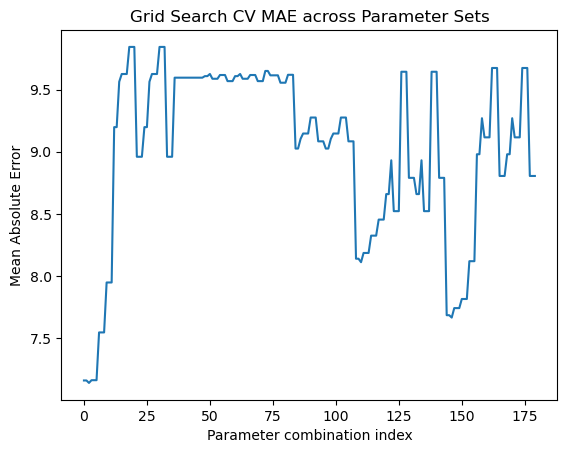


GRID SEARCH – DECISION TREE
Best params: {'max_depth': None, 'max_features': None, 'min_samples_leaf': 3, 'min_samples_split': 10}
Best CV MAE: 7.138


In [8]:
# ---------------------------------------------------------------------------
# Question 6.0 – Model Optimization (Tree or Neural Net)
# ---------------------------------------------------------------------------

from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor

# Expanded grid of hyperparameters
tree_grid = {
    'max_depth': [None, 4, 6, 8, 10],
    'min_samples_leaf': [3, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'max_features': [None, 'sqrt', 'log2']
}

# Base tree model
tree_base = DecisionTreeRegressor(random_state=39)

# Grid search with grouped CV
tree_search = GridSearchCV(
    estimator=tree_base,
    param_grid=tree_grid,
    scoring=scorer_mae,
    cv=cv,
    n_jobs=-1
)

# Fit with groups passed here
tree_search.fit(X_work, y_total, groups=groups)

# Best model and score
best_tree = tree_search.best_estimator_
best_tree_mae = -tree_search.best_score_

results = pd.DataFrame(tree_search.cv_results_)
plt.plot(results['mean_test_score']*-1)
plt.title("Grid Search CV MAE across Parameter Sets")
plt.xlabel("Parameter combination index")
plt.ylabel("Mean Absolute Error")
plt.show()

# Report results
print("\n" + "="*70)
print("GRID SEARCH – DECISION TREE")
print("="*70)
print("Best params:", tree_search.best_params_)
print(f"Best CV MAE: {best_tree_mae:.3f}")

